### Human in the Loop

In [1]:
#Build our entire graph
import os
from langchain.chat_models import init_chat_model # generic way
llm = init_chat_model("groq:openai/gpt-oss-120b") #groq: write initally

In [2]:
from typing import Annotated

from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from typing_extensions import TypedDict

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from langgraph.types import Command, interrupt # frocefully interrupting a workflow for human in loop

class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

@tool
def human_assistance(query: str) -> str:
    """Request assistance from a human."""
    human_response = interrupt({"query": query})
    return human_response["data"]

tool = TavilySearch(max_results=2)
tools = [tool, human_assistance]
llm_with_tools = llm.bind_tools(tools)

def chatbot(state: State):
    message = llm_with_tools.invoke(state["messages"])
    # Because we will be interrupting during tool execution,
    # we disable parallel tool calling to avoid repeating any
    # tool invocations when we resume.
    
    return {"messages": [message]}

graph_builder.add_node("chatbot", chatbot)

tool_node = ToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)

graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition,
)
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START, "chatbot")

In [3]:
memory = MemorySaver()

graph = graph_builder.compile(checkpointer=memory)

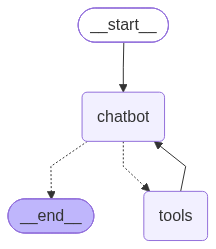

In [4]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    # This requires some extra dependencies and is optional
    pass

In [ ]:
user_input = "I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?"
config = {"configurable": {"thread_id": "1"}}

events = graph.stream(
    {"messages": user_input},
    config,
    stream_mode="values",
)
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need some expert guidance for building an AI agent. Could you request assistance for me?
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_9c202c9c-6fdf-40c9-ba07-751f9c44aca7)
 Call ID: fc_9c202c9c-6fdf-40c9-ba07-751f9c44aca7
  Args:
    query: User requests expert guidance for building an AI agent.
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_9c202c9c-6fdf-40c9-ba07-751f9c44aca7)
 Call ID: fc_9c202c9c-6fdf-40c9-ba07-751f9c44aca7
  Args:
    query: User requests expert guidance for building an AI agent.


In [6]:
human_response = (
    "We, the experts are here to help! We'd recommend you check out LangGraph to build your agent."
    " It's much more reliable and extensible than simple autonomous agents."
)

human_command = Command(resume={"data": human_response})

events = graph.stream(human_command, config, stream_mode="values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_55090cd5-e4f7-48c1-9db6-d6cc39976559)
 Call ID: fc_55090cd5-e4f7-48c1-9db6-d6cc39976559
  Args:
    query: User requests expert guidance and assistance for building an AI agent.
================================= Tool Message =================================
Name: human_assistance

We, the experts are here to help! We'd recommend you check out LangGraph to build your agent. It's much more reliable and extensible than simple autonomous agents.
================================== Ai Message ==================================

Absolutely—happy to dive in and help you get started building a robust AI agent! Below is a practical, step‑by‑step guide that covers the core decisions, tools, and best practices you’ll need. Feel free to let me know which parts you’d like to explore in more depth or any specific use case you have in mind.

---

## 1️⃣ Define the Agent’s Purpose & Scop